USGS HBV


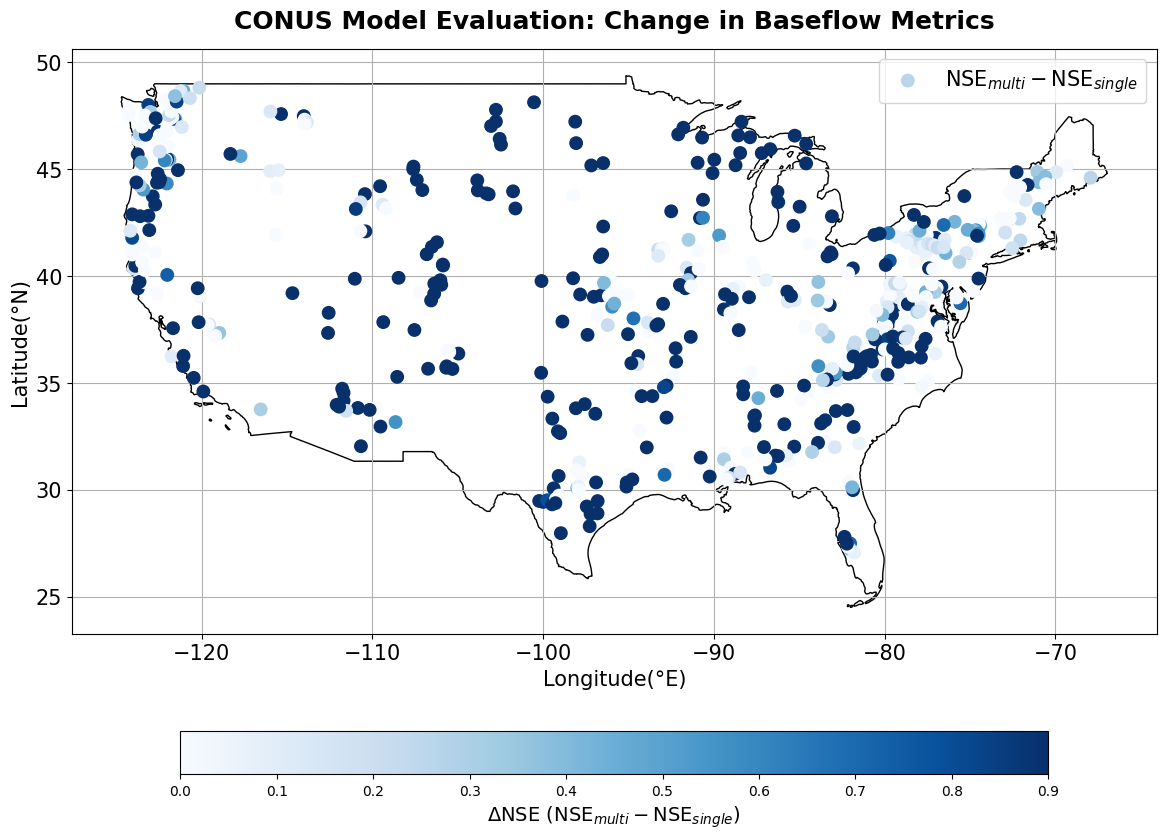

USGS marrmot_PRMS


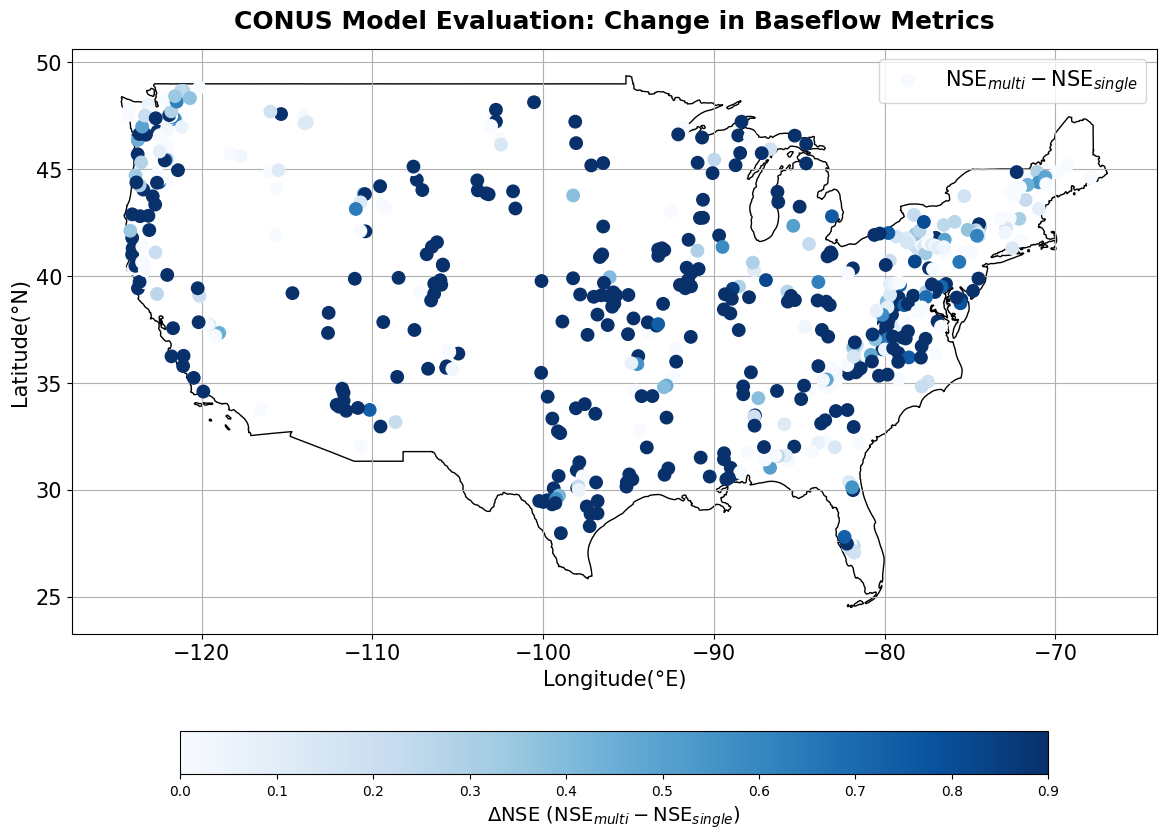

USGS HBV_capillary


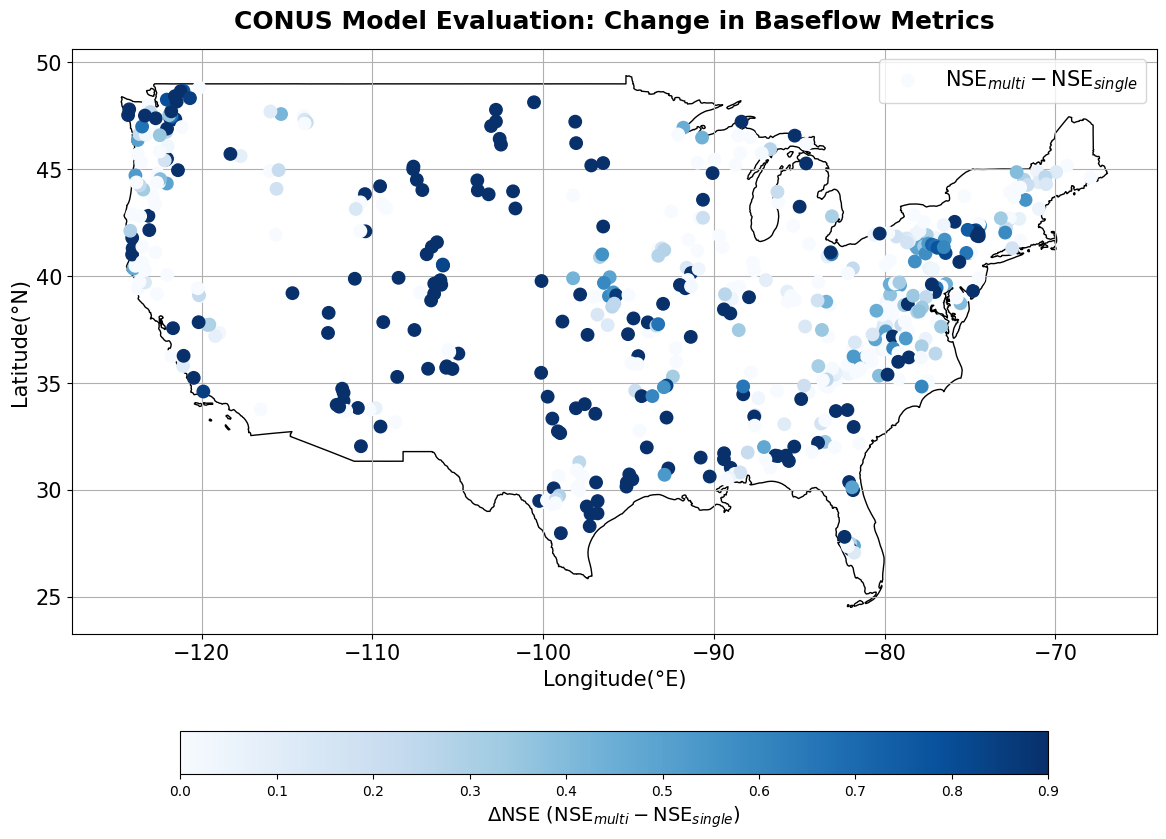

Furey HBV


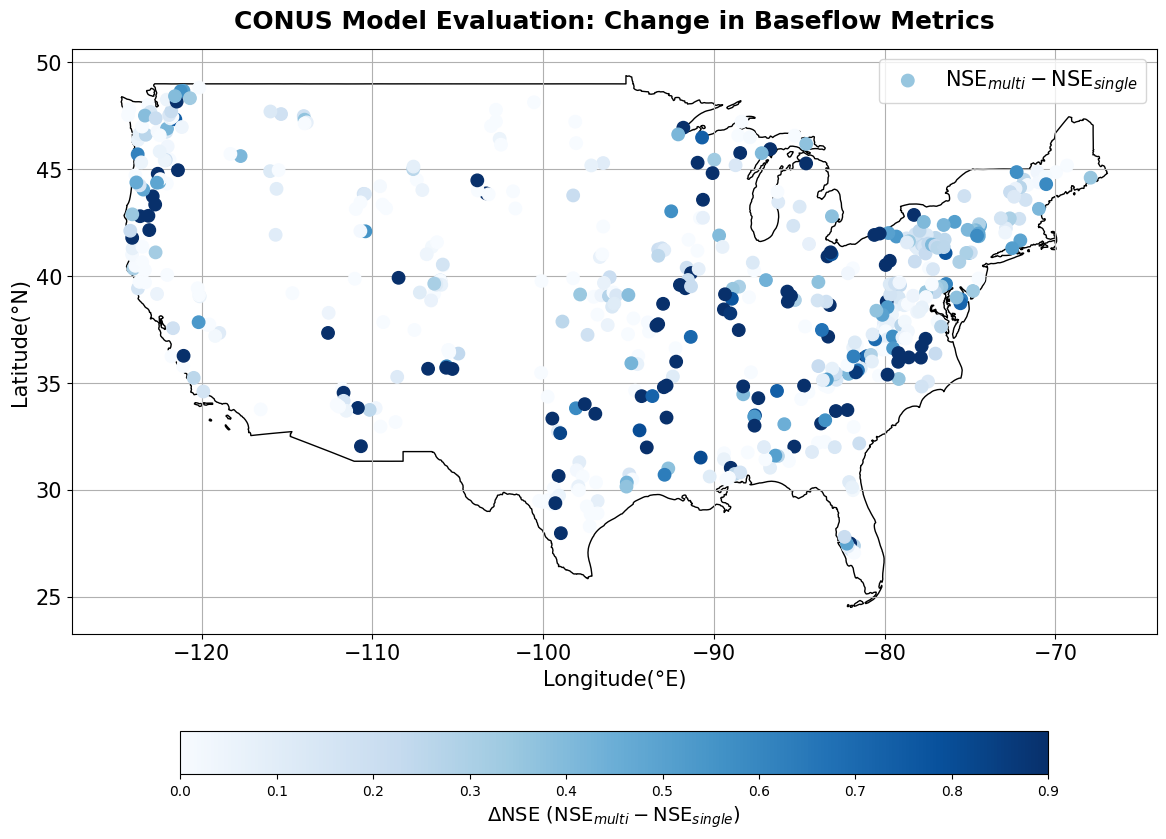

Furey marrmot_PRMS


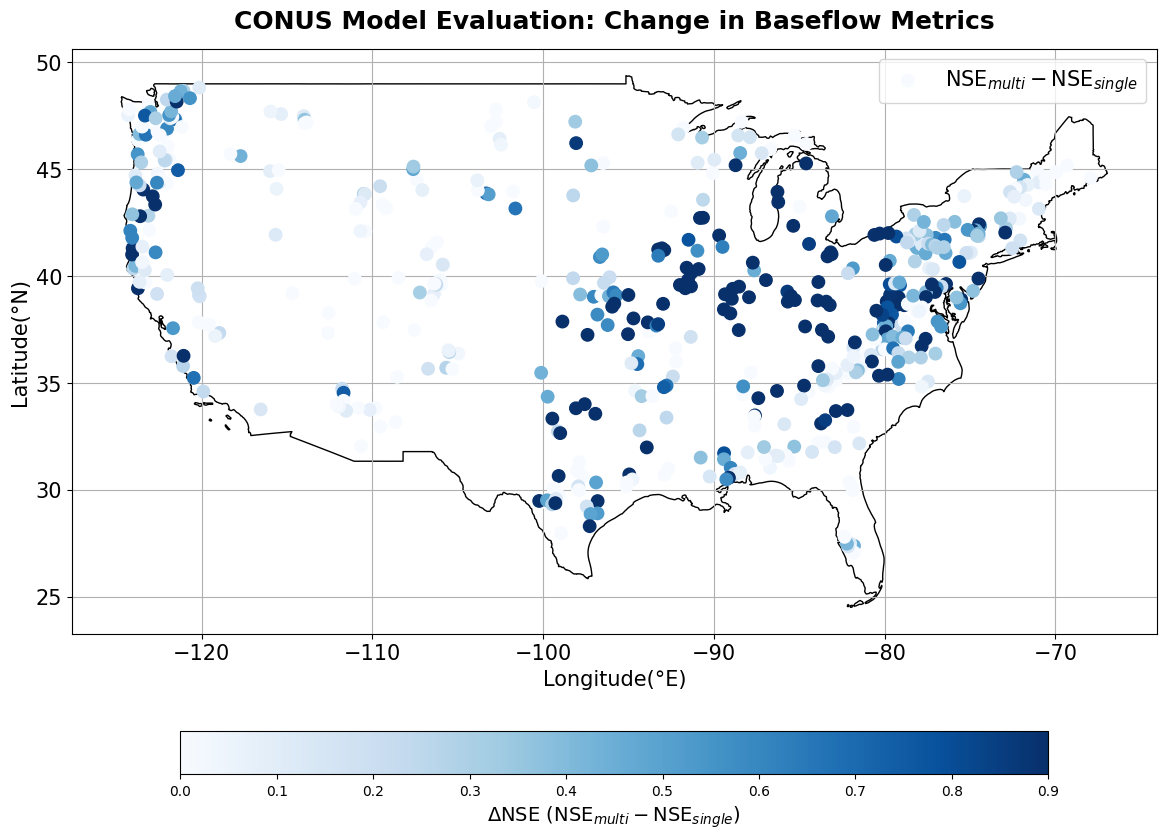

Furey HBV_capillary


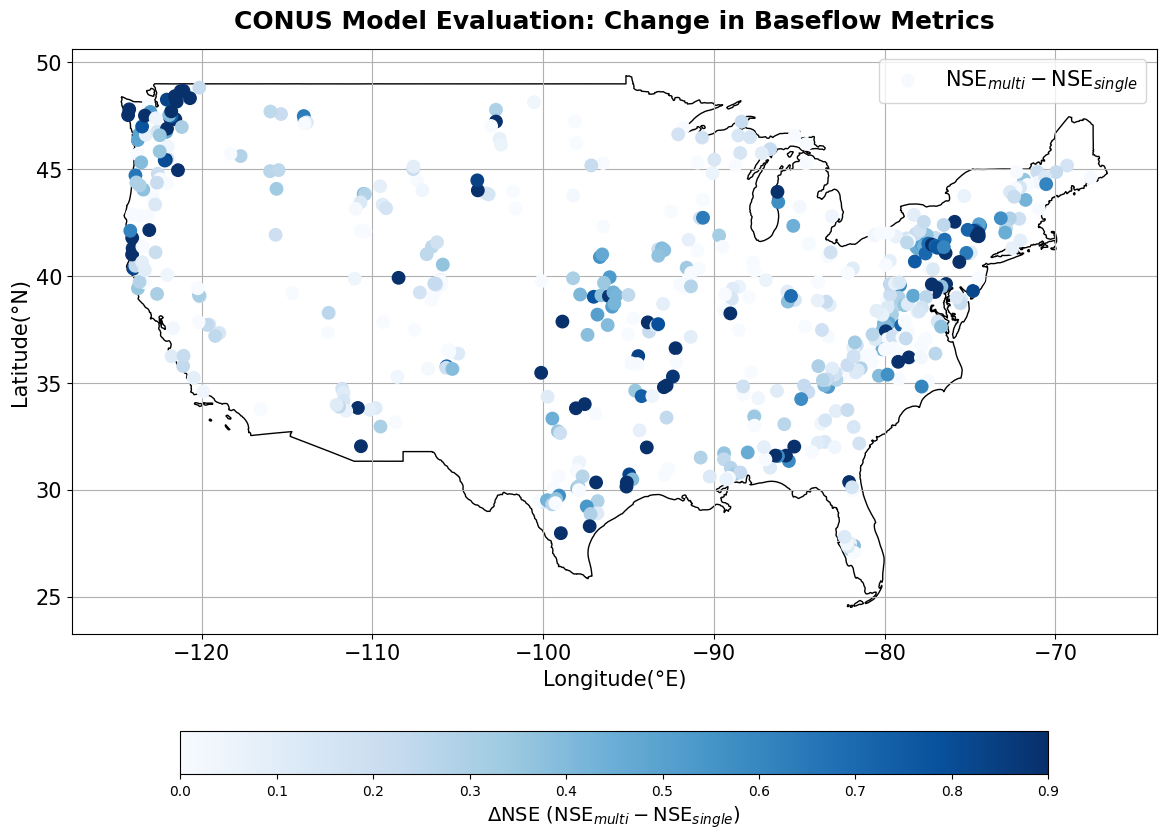

Eckhardt HBV


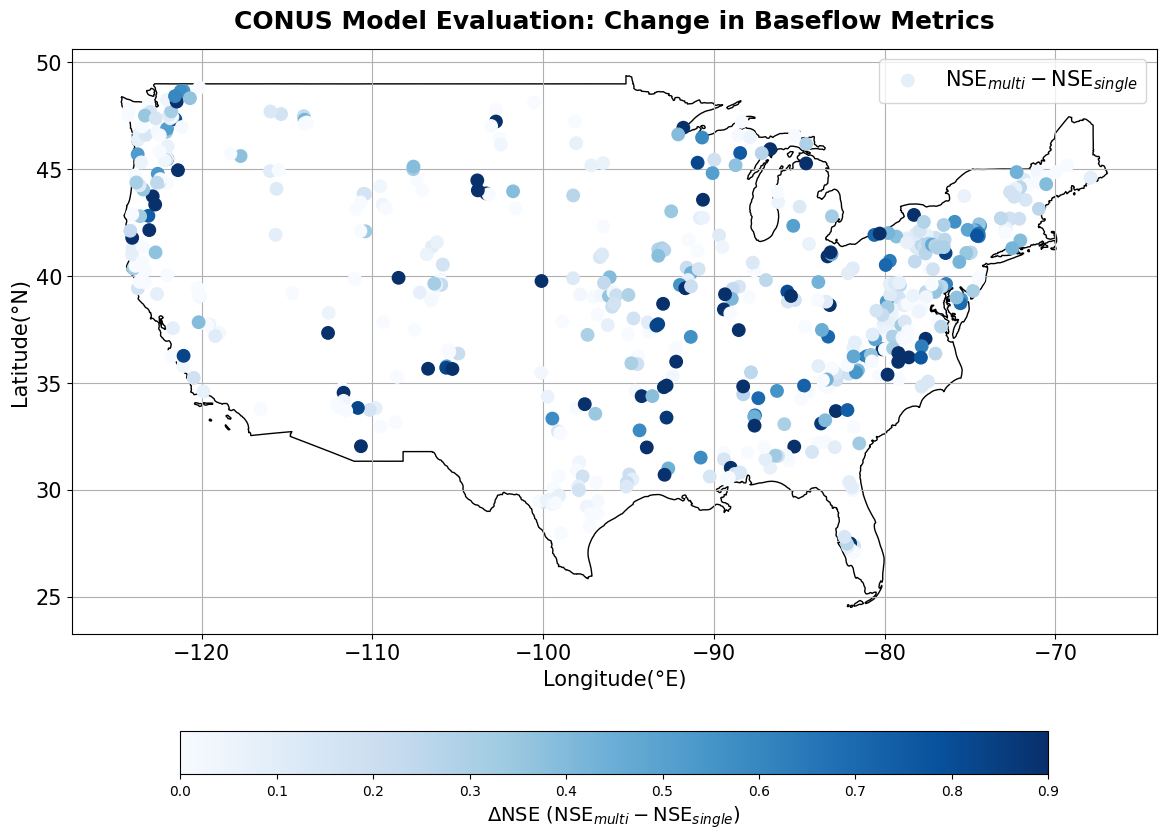

Eckhardt marrmot_PRMS


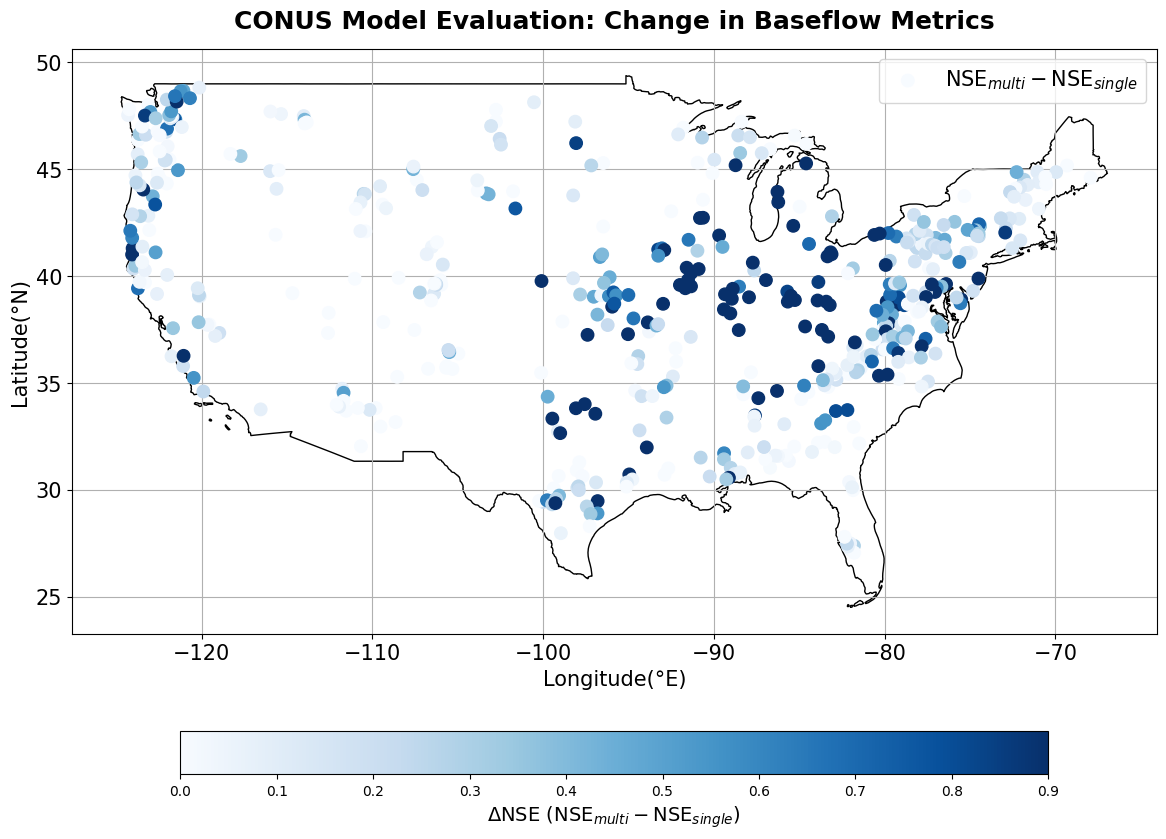

Eckhardt HBV_capillary


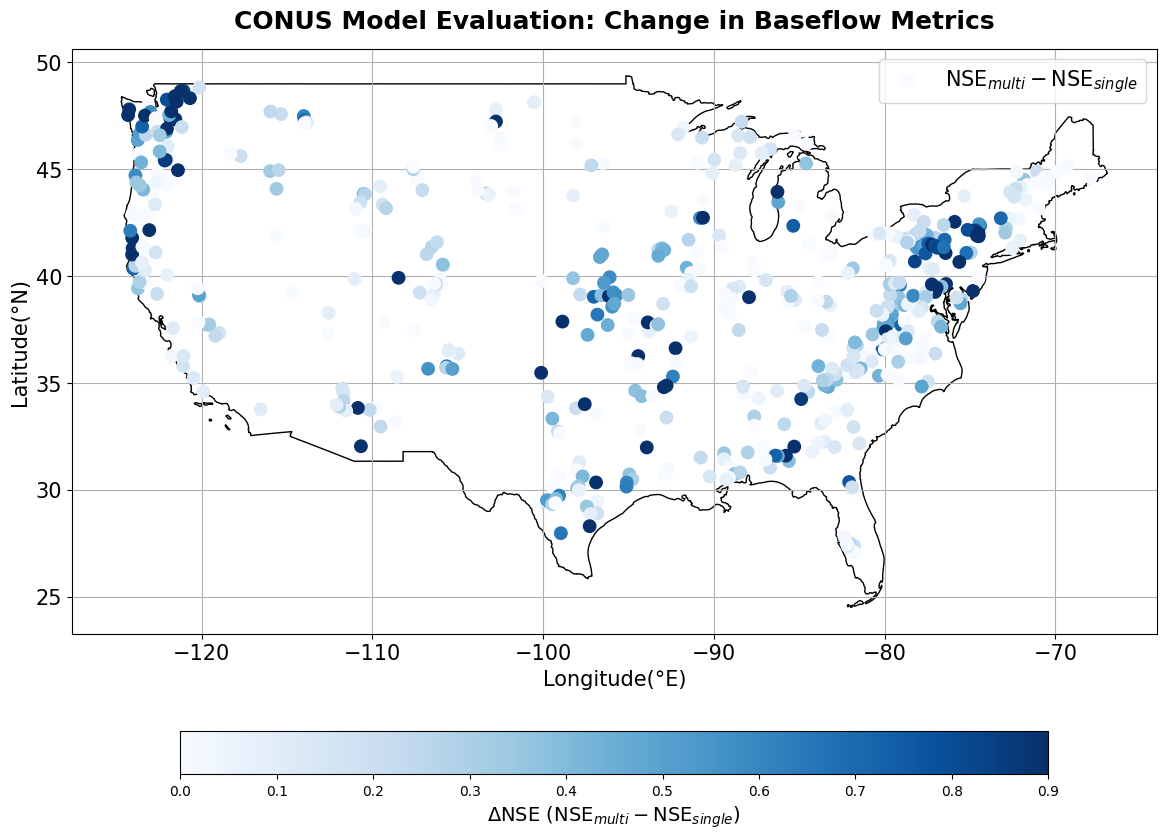

LocalHYSEP HBV


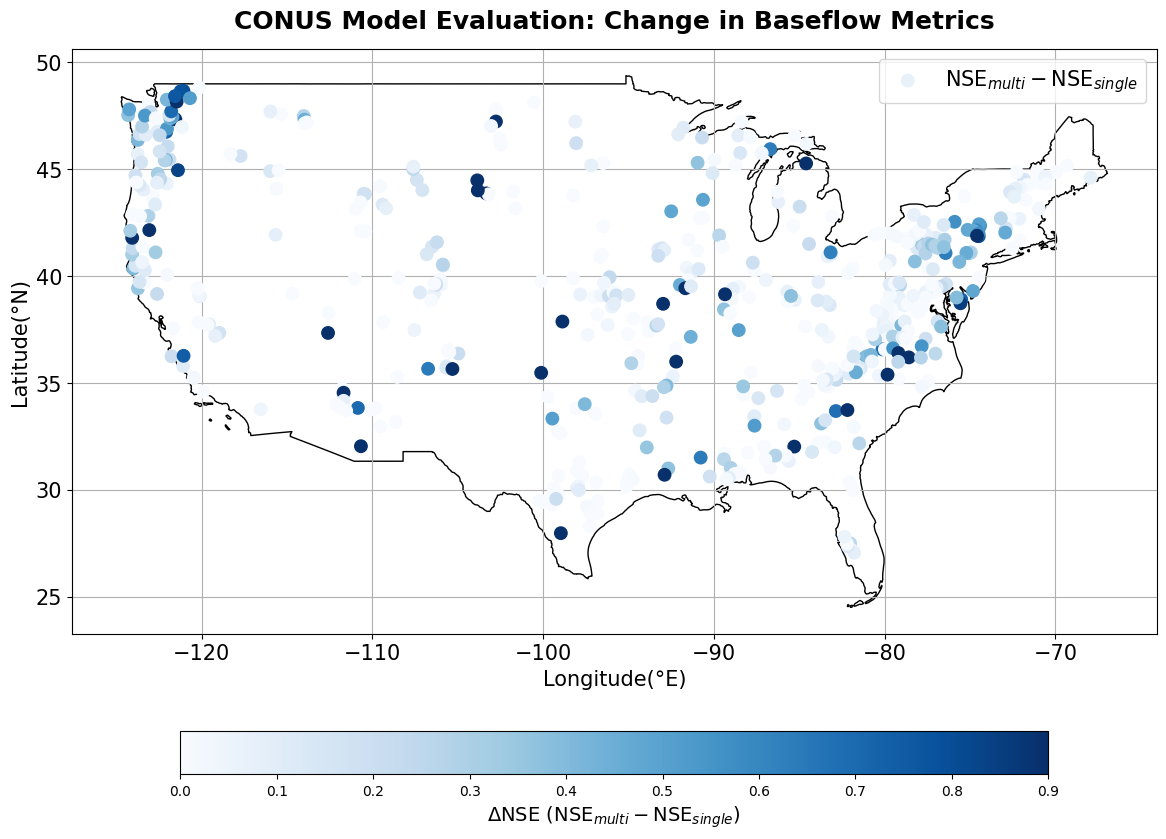

LocalHYSEP marrmot_PRMS


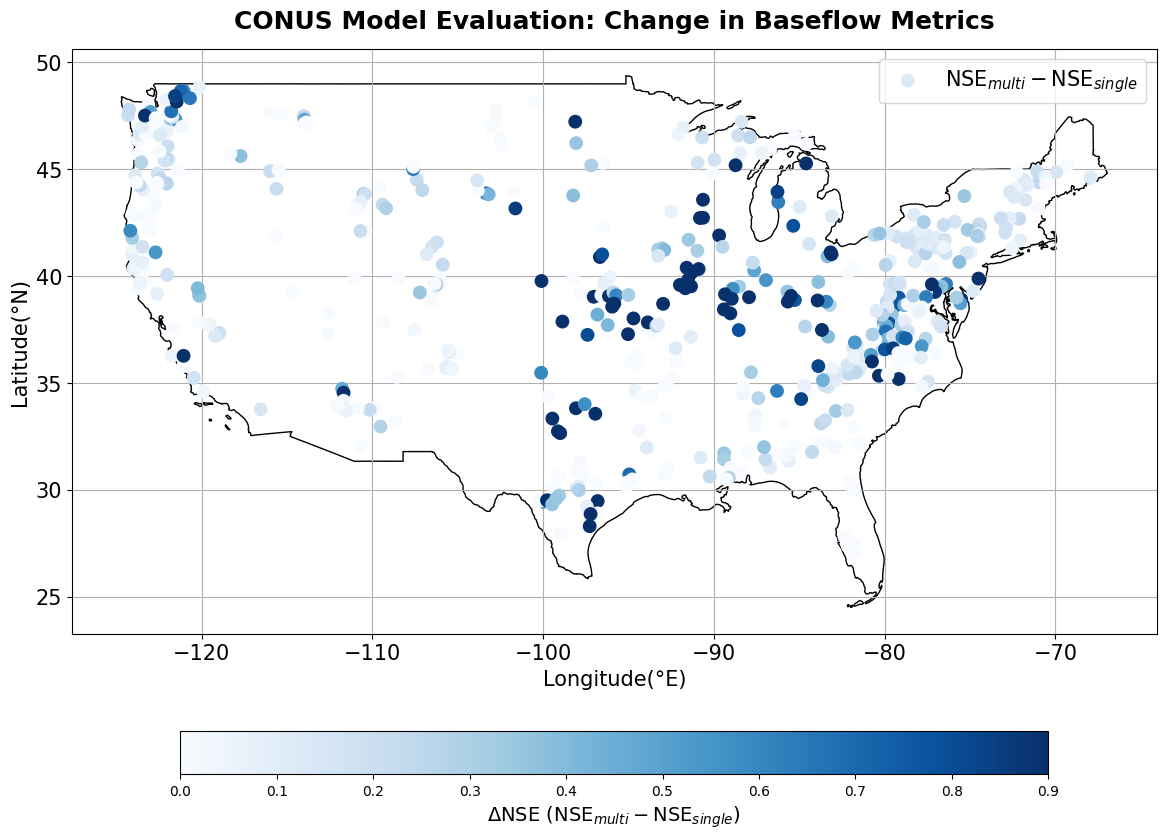

LocalHYSEP HBV_capillary


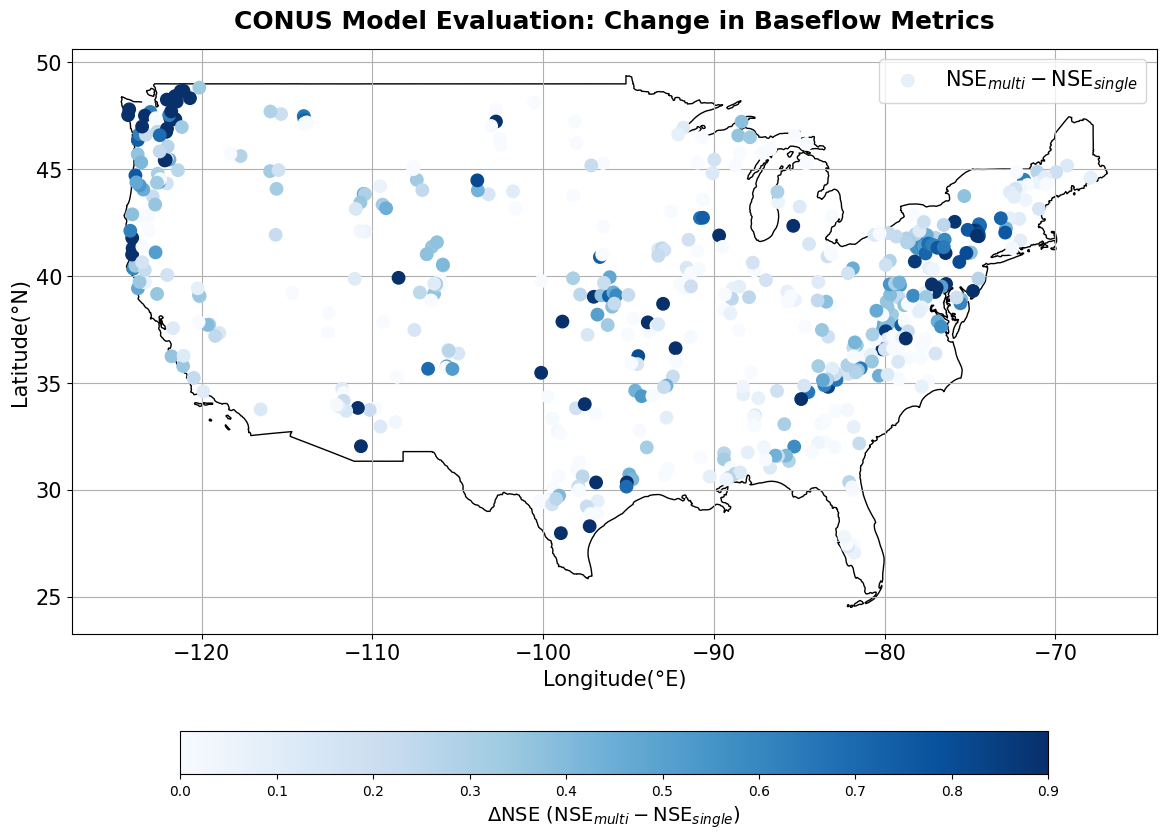

In [8]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box


gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)

## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

method= 'LocalHYSEP'
methods= ['USGS', 'Furey', 'Eckhardt', 'LocalHYSEP']
## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']


if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'

for method in methods:
    for model in models:
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                    f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/{method}_Multi/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/{method}_Multi/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/{method}_Multi/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/{method}_Multi/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)
        # Create the plot figure
        fig, ax = plt.subplots(figsize=(14, 14))
        # 1. Plot the map outline backdrop first
        gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)
        # 2. Plot Single-Objective performance markers (Square shape)
        scatter1 = ax.scatter(
            table['lon'], table['lat'], 
            marker='o', s=80, 
            c=table['NSE-Flow (Single-Objective)'], 
            cmap='Blues', vmin=0.2, vmax=1,  # Set color limits for clear NSE comparison
            label='Single-Objective', zorder=2
        )
        # 4. Generate discrete colorbars for both objectives
        cbar1 = fig.colorbar(scatter1, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
        cbar1.set_label('NSE Flow (Single-Objective)')
        # 5. Finalize legend and axis view configurations
        plt.legend(loc='upper right', fontsize=15)
        ax.set_title("CONUS Streamflow Model Evaluation: NSE Flow Metrics", fontsize=18, fontweight='bold', pad=15)
        # ax.set_axis_off()  # Optional: hides degree grid lines for a cleaner look
        plt.xlabel('Longitude (°E)', fontsize=15)  # Corrected to °W for CONUS coordinates
        plt.ylabel('Latitude (°N)', fontsize=15)
        plt.xticks(fontsize=15)
        plt.yticks(fontsize=15)
        plt.grid()
        # plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1/Figures/NSE_MAPS/{test}/Single/Total_Flow_{model}.jpg",dpi=400)
        plt.close()

        # Create the plot figure
        fig, ax = plt.subplots(figsize=(14, 14))
        # 1. Plot the map outline backdrop first
        gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)
        # 3. Plot Multi-Objective performance markers (Circle shape)
        scatter2 = ax.scatter(
            table['lon'], table['lat'], 
            marker='o', s=80, 
            c=table['NSE-Flow (Multi-Objective)'], 
            cmap='Blues', vmin=0.2, vmax=1,
            label='Multi-Objective', zorder=3
        )
        cbar2 = fig.colorbar(scatter2, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
        cbar2.set_label('NSE Flow (Multi-Objective)')
        # 5. Finalize legend and axis view configurations
        plt.legend(loc='upper right', fontsize=15)
        ax.set_title("CONUS Streamflow Model Evaluation: NSE Flow Metrics", fontsize=16, fontweight='bold', pad=15)
        plt.xlabel('Longitude (°E)', fontsize=15)  # Corrected to °W for CONUS coordinates
        plt.ylabel('Latitude (°N)', fontsize=15)
        plt.xticks(fontsize=15)
        plt.yticks(fontsize=15)
        plt.grid()
        # plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1/Figures/NSE_MAPS/{test}/{method}/Total_Flow_{model}.jpg",dpi=400)
        plt.close()


        # Create the plot figure
        fig, ax = plt.subplots(figsize=(14, 14))
        # 1. Plot the map outline backdrop first
        gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)
        # 2. Plot Single-Objective performance markers (Square shape)
        scatter1 = ax.scatter(
            table['lon'], table['lat'], 
            marker='o', s=80, 
            c=table['NSE-Baseflow (Single-Objective)'], 
            cmap='Blues', vmin=0.2, vmax=1,  # Set color limits for clear NSE comparison
            label='Single-Objective', zorder=2
        )
        # 4. Generate discrete colorbars for both objectives
        cbar1 = fig.colorbar(scatter1, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
        cbar1.set_label('NSE Baseflow (Single-Objective)')
        # 5. Finalize legend and axis view configurations
        plt.legend(loc='upper right', fontsize=15)
        ax.set_title("CONUS Streamflow Model Evaluation: NSE Baseflow Metrics", fontsize=18, fontweight='bold', pad=15)
        # ax.set_axis_off()  # Optional: hides degree grid lines for a cleaner look
        plt.xlabel('Longitude (°E)', fontsize=15)  # Corrected to °W for CONUS coordinates
        plt.ylabel('Latitude (°N)', fontsize=15)
        plt.xticks(fontsize=15)
        plt.yticks(fontsize=15)
        plt.grid()
        # plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1/Figures/NSE_MAPS/{test}/Single/Baseflow_{model}.jpg",dpi=400)
        plt.close()


        # Create the plot figure
        fig, ax = plt.subplots(figsize=(14, 14))

        # 1. Plot the map outline backdrop first
        gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)

        # 3. Plot Multi-Objective performance markers (Circle shape)
        scatter2 = ax.scatter(
            table['lon'], table['lat'], 
            marker='o', s=80, 
            c=table['NSE-Baseflow (Multi-Objective)'], 
            cmap='Blues', vmin=0.2, vmax=1,
            label='Multi-Objective', zorder=3
        )

        cbar2 = fig.colorbar(scatter2, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
        cbar2.set_label('NSE Baseflow (Multi-Objective)')

        # 5. Finalize legend and axis view configurations
        plt.legend(loc='upper right', fontsize=15)
        ax.set_title("CONUS Model Evaluation: NSE Baseflow Metrics", fontsize=18, fontweight='bold', pad=15)
        # ax.set_axis_off()  # Optional: hides degree grid lines for a cleaner look
        plt.xlabel('Longitude(°E)', fontsize=15)
        plt.ylabel('Latitude(°N)', fontsize=15)
        plt.grid()
        # plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1/Figures/NSE_MAPS/{test}/{method}/Baseflow_{model}.jpg",dpi=400)
        plt.close()


        # Create the plot figure
        fig, ax = plt.subplots(figsize=(14, 14))

        # 1. Plot the map outline backdrop first
        gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)

        # 2. Plot performance markers
        scatter1 = ax.scatter(
            table['lon'], table['lat'], 
            marker='o', s=80, 
            c=(table['NSE-Flow (Multi-Objective)'] - table['NSE-Flow (Single-Objective)']), 
            cmap='seismic_r', 
            vmin=-0.4, 
            vmax=0.4,  
            label=r'$\text{NSE}_{\mathit{multi}} - \text{NSE}_{\mathit{single}}$', 
            zorder=2
        )

        # 4. Generate discrete colorbar
        cbar1 = fig.colorbar(scatter1, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
        cbar1.set_label(r'$\Delta\text{NSE}\ (\text{NSE}_{\mathit{multi}} - \text{NSE}_{\mathit{single}})$', fontsize=14)
        cbar1.ax.tick_params(labelsize=12)

        # 5. Finalize legend and axis view configurations
        leg = plt.legend(loc='upper right', fontsize=14, framealpha=1.0, facecolor='white', edgecolor='gray')

        # FORCE LEGEND ICON COLOR TO BE VISIBLE (Changes it from invisible white to solid dark blue/grey)
        for handle in leg.legend_handles:
            handle.set_color('#1f77b4')  # Solid blue color for the legend reference circle
            handle.set_sizes([100])      # Makes the legend circle slightly larger for readability

        ax.set_title("CONUS Streamflow Model Evaluation: Change in NSE Flow Metrics", fontsize=18, fontweight='bold', pad=15)
        plt.xlabel('Longitude (°E)', fontsize=15)  # Corrected to °W for CONUS coordinates
        plt.ylabel('Latitude (°N)', fontsize=15)
        plt.xticks(fontsize=15)
        plt.yticks(fontsize=15)
        plt.grid()
        plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1/Figures/NSE_MAPS/{test}/{method}/Delta_Total_Flow_{model}.jpg",dpi=400)
        plt.close()

        # Create the Delta baseflow plot figure
        fig, ax = plt.subplots(figsize=(14, 14))
        # 1. Plot the map outline backdrop first
        gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)
        # 2. Plot Single-Objective performance markers (Square shape)
        scatter1 = ax.scatter(
            table['lon'], table['lat'], 
            marker='o', s=80, 
            c= (table['NSE-Baseflow (Multi-Objective)']-table['NSE-Baseflow (Single-Objective)']), 
            cmap='Blues', 
            vmin=0, #-0.4, 
            vmax=0.9,  # Set color limits for clear NSE comparison
            label= r'$\text{NSE}_{\mathit{multi}} - \text{NSE}_{\mathit{single}}$',
            zorder= 2)

        cbar1 = fig.colorbar(scatter1, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
        cbar1.set_label(r'$\Delta\text{NSE}\ (\text{NSE}_{\mathit{multi}} - \text{NSE}_{\mathit{single}})$', fontsize=14)

        # 5. Finalize legend and axis view configurations
        plt.legend(loc='upper right', fontsize=15)
        ax.set_title("CONUS Model Evaluation: Change in Baseflow Metrics", fontsize=18, fontweight='bold', pad=15)
        # ax.set_axis_off()  # Optional: hides degree grid lines for a cleaner look
        plt.xlabel('Longitude(°E)', fontsize=15)
        plt.ylabel('Latitude(°N)', fontsize=15)
        plt.xticks(fontsize=15)
        plt.yticks(fontsize=15)
        plt.grid()
        print(method,model)
        # plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1/Figures/NSE_MAPS/{test}/{method}/Delta_Baseflow_{model}.jpg",dpi=400)
        plt.show()
                        
                    
